Analyze feature importance in ensemble models using permutation importance, SHAP values, and gain-based metrics, and visualize their contributions to enhance model interpretability and decision-making.

In [4]:
import pandas as pd
import numpy as np

In [5]:
np.random.seed(42)

In [6]:
n_samples = 600

In [7]:
age = np.random.normal(60, 10, n_samples).clip(25, 85)
apache_score = np.random.poisson(lam=18, size=n_samples).clip(5, 45)
creatinine = np.random.exponential(scale=1.2, size=n_samples).round(2)
white_blood_cells = np.random.normal(11, 4, n_samples).clip(2, 30).round(1)
spo2 = np.random.normal(95, 3, n_samples).clip(75, 100).round(1)

In [8]:
random_noise = np.random.uniform(0, 100, n_samples).round(2)

In [9]:
risk_logits = (
    0.04 * (age - 60)
    + 0.12 * (apache_score - 18)
    + 0.6 * creatinine
    + 0.15 * (white_blood_cells - 11)
    - 0.25 * (spo2 - 95)
    + 0.02 * (apache_score - 18) * creatinine # Interaction
)

In [10]:
probs = 1 / (1 + np.exp(-risk_logits))
target = (probs > np.median(probs)).astype(int)

In [11]:
df_explain = pd.DataFrame({
    'age': age.round(1),
    'apache_score': apache_score,
    'creatinine': creatinine,
    'white_blood_cells': white_blood_cells,
    'spo2': spo2,
    'random_noise': random_noise,
    'icu_readmit': target
})

In [12]:
print("Dataset Shape:", df_explain.shape)
print("ICU Readmission Target Distribution:\n", df_explain['icu_readmit'].value_counts())

Dataset Shape: (600, 7)
ICU Readmission Target Distribution:
 icu_readmit
0    300
1    300
Name: count, dtype: int64


In [13]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, roc_auc_score

In [14]:
X = df_explain.drop(columns=['icu_readmit'])
y = df_explain['icu_readmit']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [16]:
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

In [17]:
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=None,
              num_parallel_tree=None, ...)

In [18]:
print(f"Test Set F1-Score: {f1_score(y_test, xgb_model.predict(X_test)):.4f}")
print(f"Test Set ROC-AUC : {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]):.4f}")

Test Set F1-Score: 0.9333
Test Set ROC-AUC : 0.9868


In [19]:
gain_importances = pd.Series(
    xgb_model.get_booster().get_score(importance_type='gain')
).reindex(X.columns, fill_value=0).sort_values(ascending=True)

In [20]:
print("\nNative Gain Importances extracted.")


Native Gain Importances extracted.


In [21]:
from sklearn.inspection import permutation_importance

In [23]:
perm_result = permutation_importance(
    xgb_model, 
    X_test, 
    y_test, 
    scoring='roc_auc', 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1
)

In [24]:
perm_importances = pd.Series(
    perm_result.importances_mean, 
    index=X.columns
).sort_values(ascending=True)

In [25]:
print("Permutation Importances computed across 10 repeats.")

Permutation Importances computed across 10 repeats.


In [26]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.inspection import PartialDependenceDisplay, permutation_importance

In [27]:
perm_result = permutation_importance(
    xgb_model, 
    X_test, 
    y_test, 
    scoring='roc_auc', 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1
)

In [28]:
perm_importances = pd.Series(
    perm_result.importances_mean, 
    index=X.columns
).sort_values(ascending=True)

In [29]:
gain_importances = pd.Series(
    xgb_model.get_booster().get_score(importance_type='gain')
).reindex(X.columns, fill_value=0).sort_values(ascending=True)

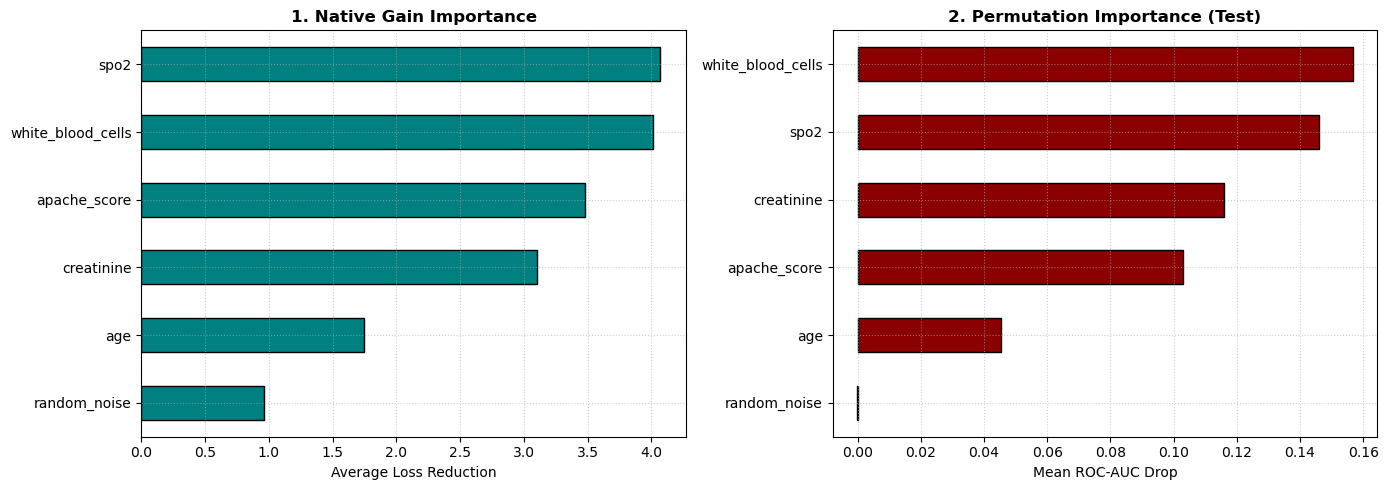

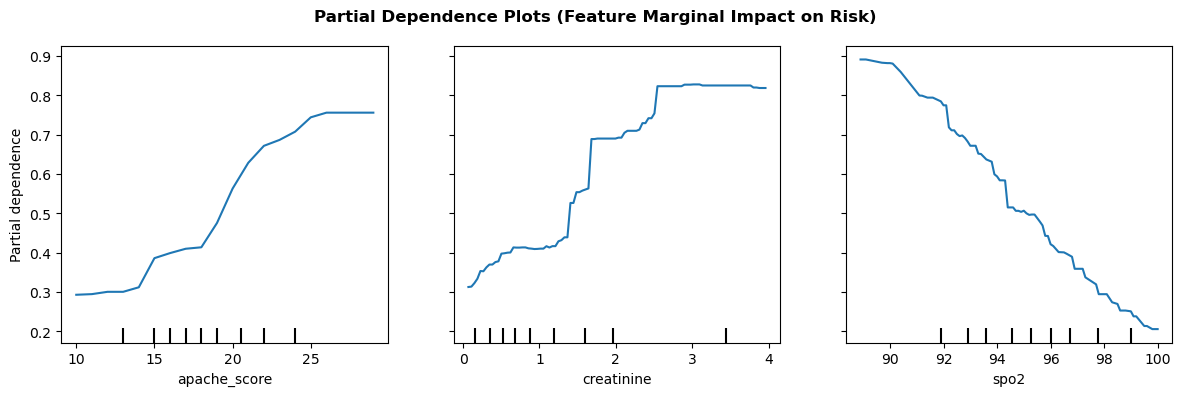

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gain_importances.plot(kind='barh', ax=axes[0], color='teal', edgecolor='black')
axes[0].set_title("1. Native Gain Importance", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Average Loss Reduction", fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

perm_importances.plot(kind='barh', ax=axes[1], color='darkred', edgecolor='black')
axes[1].set_title("2. Permutation Importance (Test)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Mean ROC-AUC Drop", fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. Partial Dependence Plots for Top Risk Features
fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    xgb_model,
    X_test,
    features=['apache_score', 'creatinine', 'spo2'],
    ax=ax
)
plt.suptitle("Partial Dependence Plots (Feature Marginal Impact on Risk)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()